# Final Project — Verifying YOLOv8n Pedestrian Detections with Machine Learning

**Student:** Bolatov Bekdaulet, SE-2405 (solo project) &nbsp;|&nbsp; **Course:** Machine Learning (AMO 3208) &nbsp;|&nbsp; **Instructor:** Mimenbayeva A.B.

This notebook is the code of my final project. It joins my **Assignment 2** (problem, literature, the dataset
*PedCrops v1*), my **endterm** (own CNN and MobileNetV2) and the new parts of the final project: a classical
model (**HOG + SVM**), a comparison of **preprocessing methods**, a comparison of the **three models**, and a
**web application**. Everything is connected to my diploma system *public.safe* (phones as cameras, YOLOv8n finds
people in danger zones). My models check every YOLOv8n "person" box and remove false alarms.

**Which code is which model**

| Model | Type | Section | Code |
|---|---|---|---|
| Model 1 – HOG + SVM | classical machine learning | 3 | `src/classical.py` |
| Model 2 – own CNN (3 configurations + improved CNN) | deep learning from scratch | 4 | `src/models.py` (`PedCNN`), `src/train.py` |
| Model 3 – MobileNetV2 | deep learning, transfer learning | 5 | `src/models.py` (`mobilenet_v2_transfer`) |
| Practical application: YOLOv8n + verifier, web app | application | 7, 8 | `src/verifiers.py`, `src/verified_detector.py`, `app.py` |

| Requirement of the final project | Section |
|---|---|
| Data description, cleaning, normalization, feature selection | 1, 2 |
| At least 3 preprocessing / ML methods compared | 3 (4 feature sets, 4 classifiers), 4 (3 configurations), 6 (3 models) |
| Training, validation and testing | 3–6 (train / validation / test split by photo) |
| Results with tables and figures | 3–7 |
| Working program | 7, 8 (`app.py`) |

By default `TRAIN = False`: the CNN and MobileNetV2 weights and training histories from my endterm are loaded
(training them again takes about 1.5 hours on my laptop). The classical model is always trained here (a few minutes).

In [1]:
# --- setup: works locally and in Google Colab ---
import os, sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules and not Path("src").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/BekdauletBol/ml-final-project-pedestrian-verifier.git"], check=True)
    os.chdir("ml-final-project-pedestrian-verifier")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-image"], check=True)
TRAIN = False         # True = train the CNNs and MobileNetV2 again (about 1.5 h); the SVM is always trained
print("working dir:", Path.cwd().name)

working dir: final_project


In [2]:
import json, time, io, zipfile, dataclasses
import numpy as np, pandas as pd, torch, joblib
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.metrics import f1_score
from skimage.feature import hog
from src.data import CLASSES, IMAGENET_MEAN, IMAGENET_STD, load_split, pick_device, prepare_batch, gpu_augment
from src.models import PedCNN, mobilenet_v2_transfer, set_backbone_trainable, count_params
from src.train import TrainConfig, History, fit, evaluate
from src.evaluate import metrics_dict, report, plot_confusion, plot_history
from src.classical import pixel_features, hog_features, to_gray, make_pipeline, HOG_PARAMS

sns.set_theme(style="whitegrid")
FIG = Path("results/figures"); FIG.mkdir(parents=True, exist_ok=True)
RESULTS = Path("results")
device = pick_device()
torch.manual_seed(42); np.random.seed(42)
print("torch", torch.__version__, "| device:", device)

torch 2.15.0 | device: mps


## 1. Materials — the dataset *PedCrops v1*

I built the dataset in Assignment 2 (`data/build_dataset.py`) from **COCO val2017** (4,952 photos, 36,781
human-made boxes; Hugging Face mirror `detection-datasets/coco`). Every sample is a 128×128 RGB crop of one box
(10 % context, gray letterbox padding like YOLO) with one of three labels: **pedestrian** (COCO person boxes),
**other_object** (boxes of the other 79 COCO classes that do not overlap a person) and **background** (random
person-shaped windows without objects). The split is 70 / 15 / 15 **by photo**, so no photo is in two splits.

In [3]:
DATA = Path("data/pedcrops_v1")
stats = json.loads((DATA / "stats.json").read_text())
x_train, y_train, m_train = load_split(DATA, "train")
x_val, y_val, m_val = load_split(DATA, "val")
x_test, y_test, m_test = load_split(DATA, "test")
yt_np = y_test.numpy()
print("train", tuple(x_train.shape), "val", tuple(x_val.shape), "test", tuple(x_test.shape), "| dtype", x_train.dtype)
dist = pd.DataFrame({s: pd.Series(y.numpy()).map(dict(enumerate(CLASSES))).value_counts() for s, y in
                     [("train", y_train), ("val", y_val), ("test", y_test)]})
dist.loc["total"] = dist.sum(); dist["total"] = dist.sum(axis=1)
dist

train (15260, 3, 128, 128) val (3324, 3, 128, 128) test (3085, 3, 128, 128) | dtype torch.uint8


,train,val,test,total
background,5078,1052,1093,7223
other_object,5019,1132,1072,7223
pedestrian,5163,1140,920,7223
total,15260,3324,3085,21669


In [4]:
# structure of metadata.csv: one row per crop (the image itself is in train/val/test.zip)
meta = pd.read_csv(DATA / "metadata.csv")
describe = {
    "crop_id": "ID of the crop", "image_id": "ID of the COCO photo", "label": "class name (target)",
    "label_id": "class number 0/1/2 (target)", "source": "COCO class of the box or random_window",
    "x1": "box left, px", "y1": "box top, px", "x2": "box right, px", "y2": "box bottom, px",
    "box_w": "box width, px", "box_h": "box height, px", "img_w": "photo width, px", "img_h": "photo height, px",
    "touches_border": "box touches the photo border", "split": "train / val / test", "file": "path in the zip",
}
kind = {"object": "categorical / text", "str": "categorical / text", "int64": "integer",
        "float64": "numeric (continuous)", "bool": "boolean"}
pd.DataFrame({"type": [kind[str(meta[c].dtype)] for c in meta.columns],
              "unique values": [meta[c].nunique() for c in meta.columns],
              "example": [meta[c].iloc[0] for c in meta.columns],
              "meaning": [describe[c] for c in meta.columns]}, index=meta.columns)

,type,unique values,example,meaning
crop_id,categorical / text,21669,000000000632_000018,ID of the crop
image_id,integer,4911,632,ID of the COCO photo
label,categorical / text,3,background,class name (target)
label_id,integer,3,2,class number 0/1/2 (target)
source,categorical / text,79,random_window,COCO class of the box or random_window
x1,numeric (continuous),5634,433.9,"box left, px"
y1,numeric (continuous),4429,370.4,"box top, px"
x2,numeric (continuous),5815,491.3,"box right, px"
y2,numeric (continuous),5198,470.6,"box bottom, px"
box_w,numeric (continuous),3850,57.4,"box width, px"


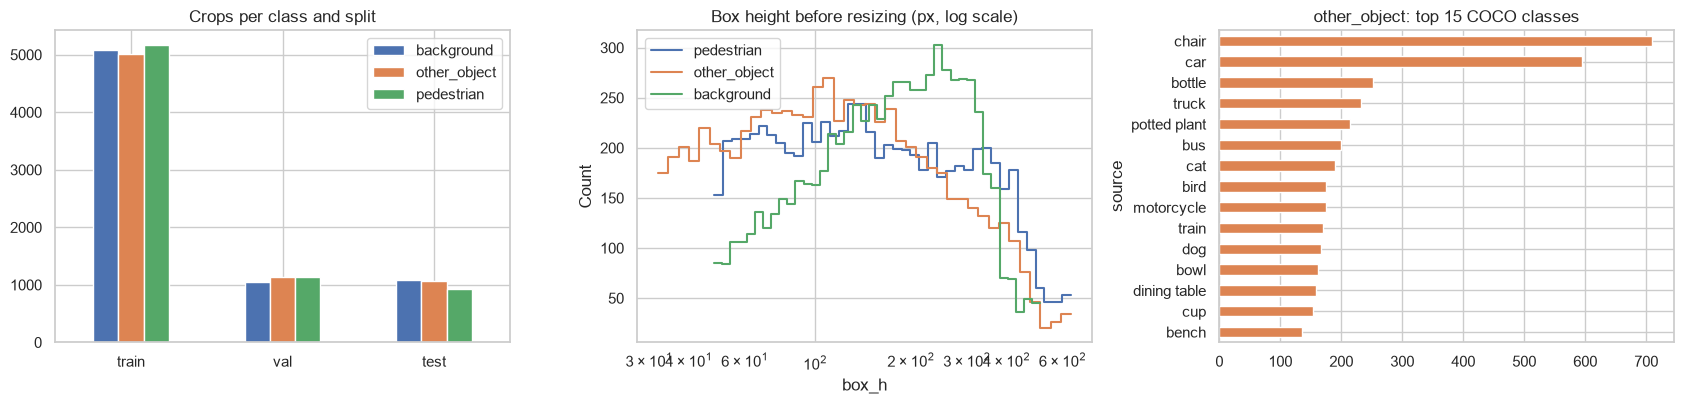

box height median (px): {'background': 173.5, 'other_object': 111.1, 'pedestrian': 145.1}


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
dist.drop(index="total", columns="total").T.plot.bar(ax=axes[0], rot=0); axes[0].set_title("Crops per class and split")
for c in CLASSES:
    sns.histplot(meta.loc[meta.label == c, "box_h"], bins=40, log_scale=True, element="step", fill=False, ax=axes[1], label=c)
axes[1].legend(); axes[1].set_title("Box height before resizing (px, log scale)")
top = meta.loc[meta.label == "other_object", "source"].value_counts().head(15)
top.sort_values().plot.barh(ax=axes[2], color="C1"); axes[2].set_title("other_object: top 15 COCO classes")
fig.tight_layout(); fig.savefig(FIG / "eda.png", dpi=130); plt.show()
print("box height median (px):", meta.groupby("label").box_h.median().round(1).to_dict())

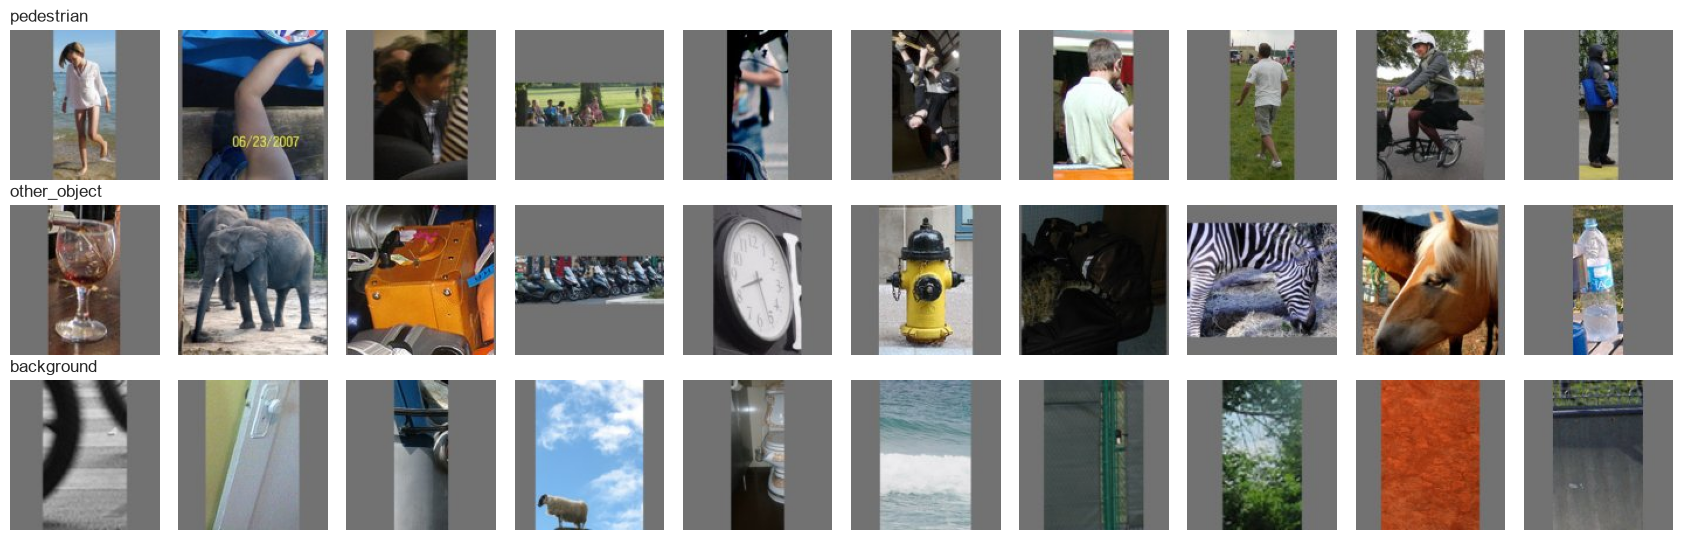

In [6]:
fig, axes = plt.subplots(3, 10, figsize=(17, 5.5))
for r, c in enumerate(CLASSES):
    idx = np.random.default_rng(1).choice(np.where(y_train.numpy() == r)[0], 10, replace=False)
    for k, i in enumerate(idx):
        axes[r, k].imshow(x_train[i].permute(1, 2, 0)); axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left")
fig.tight_layout(); fig.savefig(FIG / "dataset_samples.png", dpi=120); plt.show()

In [7]:
# data cleaning in Assignment 2 (numbers from stats.json)
cl = stats["cleaning"]
pd.Series({
    "photos read": cl["images"], "corrupted photos": cl["corrupted"], "duplicate photos": cl["duplicates"],
    "gray photos converted to RGB": cl["gray_converted"],
    "person boxes removed (too small)": cl["person_too_small"],
    "object boxes removed (overlap a person)": cl["object_overlap_person"],
    "object boxes removed (too small)": cl["object_too_small"],
    "background windows rejected (overlap)": cl["bg_rejected"],
    "duplicate crops removed (average hash)": cl["duplicate_crops"],
}, name="count").to_frame()

,count
photos read,4952
corrupted photos,0
duplicate photos,0
gray photos converted to RGB,10
person boxes removed (too small),3735
object boxes removed (overlap a person),3800
object boxes removed (too small),10793
background windows rejected (overlap),33831
duplicate crops removed (average hash),1074


## 2. Preprocessing and feature selection

* **Resize:** crops are 128×128; my CNN uses 64×64, MobileNetV2 128×128, the classical model 64×64 gray (HOG) or
  32×32 gray (raw pixels).
* **Normalization (z-score):** $z = (x-\mu)/\sigma$ per channel. CNN: mean/std of the training crops;
  MobileNetV2: ImageNet mean/std; classical features: `StandardScaler` fitted on the training set only.
* **Augmentation (CNN training only):** flip, rotation ±15°, scale 0.85–1.15, shift ±10 %, brightness/contrast ±20 %.
* **Feature extraction for the classical model:** HOG (histograms of oriented gradients), 1,764 values per crop.
* **Feature selection / reduction:** ANOVA F-test (`SelectKBest`) and PCA (95 % of the variance).

CNN normalization  mean (0.4482, 0.4267, 0.4039) std (0.2063, 0.2004, 0.2072)
MobileNetV2 (ImageNet) mean (0.485, 0.456, 0.406) std (0.229, 0.224, 0.225)


normalized CNN batch: (512, 3, 64, 64) mean 0.004 std 0.917


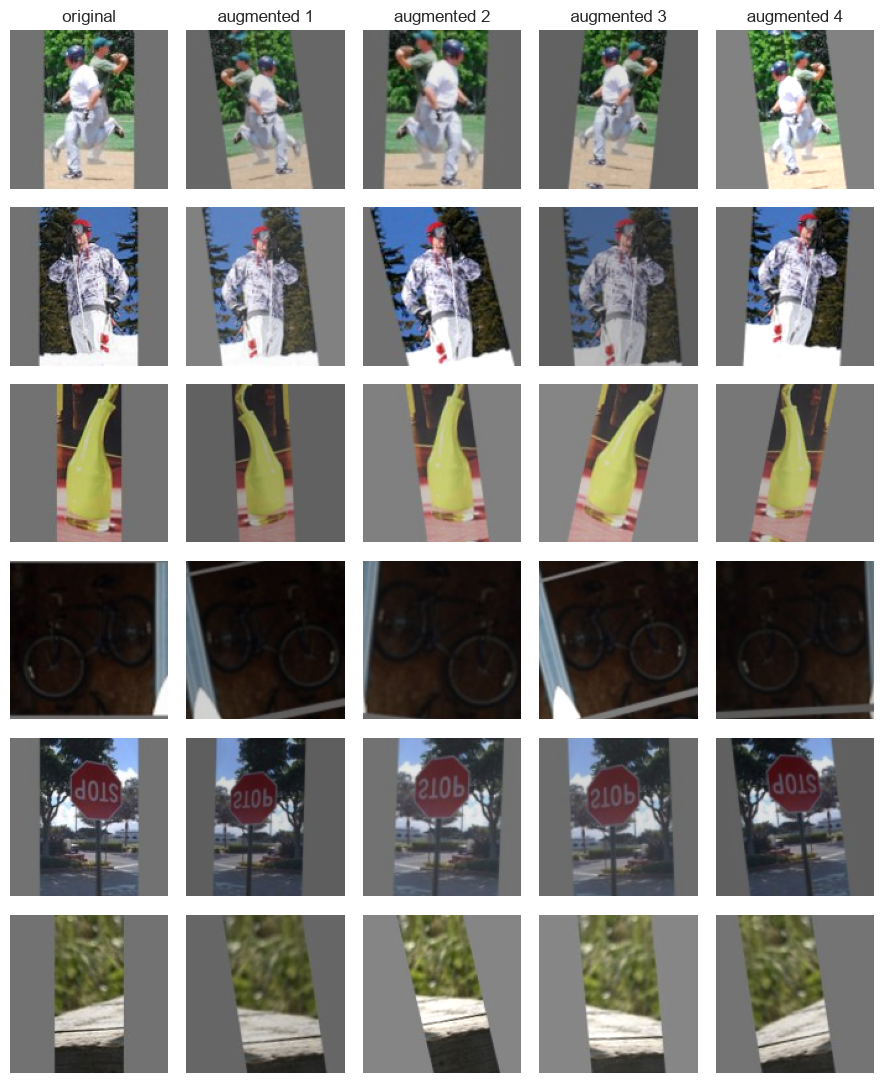

In [8]:
CNN_MEAN, CNN_STD = tuple(stats["normalization"]["mean"]), tuple(stats["normalization"]["std"])
print("CNN normalization  mean", CNN_MEAN, "std", CNN_STD)
print("MobileNetV2 (ImageNet) mean", IMAGENET_MEAN, "std", IMAGENET_STD)
xb = prepare_batch(x_train[torch.randperm(len(x_train))[:512]], device, 64, CNN_MEAN, CNN_STD)
print("normalized CNN batch:", tuple(xb.shape), "mean %.3f std %.3f" % (xb.mean().item(), xb.std().item()))

torch.manual_seed(3)
pick = torch.cat([torch.where(y_train == c)[0][[3, 40]] for c in range(3)])
base = x_train[pick].float() / 255
rows = [base] + [gpu_augment(base, 1.0) for _ in range(4)]
fig, axes = plt.subplots(len(pick), 5, figsize=(9, 11))
for j, batch in enumerate(rows):
    for i in range(len(pick)):
        axes[i, j].imshow(batch[i].permute(1, 2, 0).clamp(0, 1)); axes[i, j].axis("off")
    axes[0, j].set_title("original" if j == 0 else f"augmented {j}")
fig.tight_layout(); fig.savefig(FIG / "augmentation.png", dpi=110); plt.show()

raw pixels: 1024 features (2.6 s) | HOG: 1764 features (38.3 s)


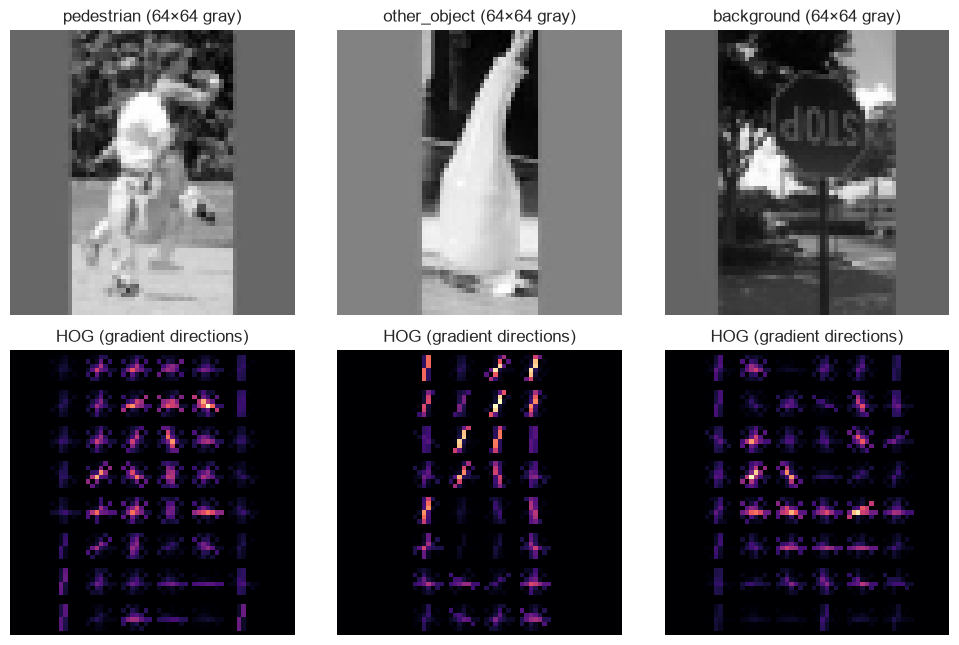

In [9]:
# features for the classical model
t0 = time.perf_counter()
P = {s: pixel_features(x) for s, x in [("train", x_train), ("val", x_val), ("test", x_test)]}
t1 = time.perf_counter()
H = {s: hog_features(x) for s, x in [("train", x_train), ("val", x_val), ("test", x_test)]}
t2 = time.perf_counter()
print(f"raw pixels: {P['train'].shape[1]} features ({t1 - t0:.1f} s) | HOG: {H['train'].shape[1]} features ({t2 - t1:.1f} s)")
ytr, yva = y_train.numpy(), y_val.numpy()

# what HOG "sees": one crop per class
fig, axes = plt.subplots(2, 3, figsize=(10, 6.6))
for j, c in enumerate(range(3)):
    i = int(torch.where(y_train == c)[0][3])
    g = to_gray(x_train[i:i + 1], 64)[0]
    _, vis = hog(g, visualize=True, **HOG_PARAMS)
    axes[0, j].imshow(g, cmap="gray"); axes[0, j].set_title(f"{CLASSES[c]} (64×64 gray)")
    axes[1, j].imshow(vis, cmap="magma"); axes[1, j].set_title("HOG (gradient directions)")
    for a in axes[:, j]: a.axis("off")
fig.tight_layout(); fig.savefig(FIG / "hog_examples.png", dpi=120); plt.show()

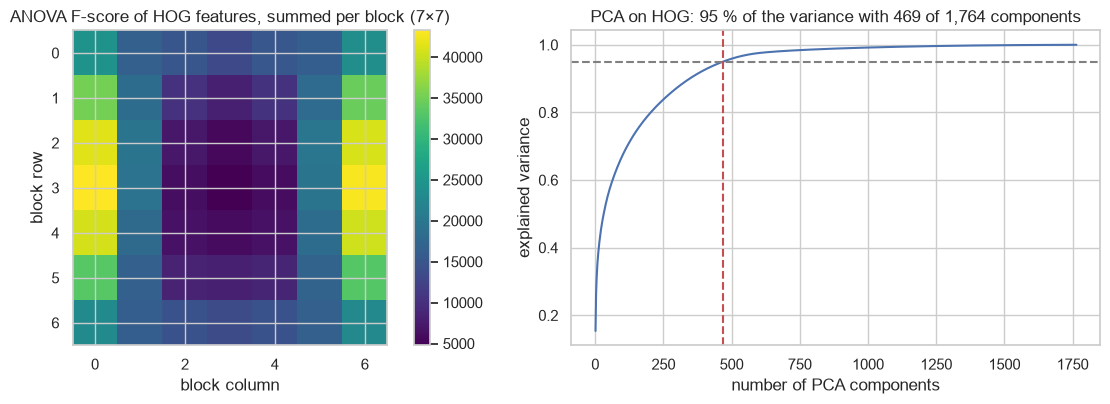

top-10 ANOVA F-scores: [2798.5 2775.9 2753.2 2745.7 2726.3 2721.7 2702.3 2686.1 2669.5 2652.4]


In [10]:
from sklearn.feature_selection import f_classif
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
F, _ = f_classif(H["train"], ytr)
pca = PCA(random_state=42).fit(StandardScaler().fit_transform(H["train"]))
cum = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.searchsorted(cum, 0.95) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
im = axes[0].imshow(F.reshape(7, 7, 2, 2, 9).sum(axis=(2, 3, 4)), cmap="viridis")
axes[0].set_title("ANOVA F-score of HOG features, summed per block (7×7)"); plt.colorbar(im, ax=axes[0])
axes[0].set_xlabel("block column"); axes[0].set_ylabel("block row")
axes[1].plot(np.arange(1, len(cum) + 1), cum); axes[1].axhline(0.95, ls="--", c="gray")
axes[1].axvline(n95, ls="--", c="C3"); axes[1].set_xlabel("number of PCA components"); axes[1].set_ylabel("explained variance")
axes[1].set_title(f"PCA on HOG: 95 % of the variance with {n95} of 1,764 components")
fig.tight_layout(); fig.savefig(FIG / "feature_selection.png", dpi=130); plt.show()
print("top-10 ANOVA F-scores:", np.sort(F)[::-1][:10].round(1))

## 3. Model 1 — HOG + SVM (classical machine learning)

**Step 1 – compare preprocessing (feature) methods** with the same classifier (linear SVM, $C=0.001$, chosen on
the validation set): raw pixels, HOG, HOG + ANOVA feature selection, HOG + PCA.
**Step 2 – compare classifiers** on the HOG features: logistic regression, random forest, linear SVM and SVM with
an RBF kernel. The best pipeline on the **validation set** is my Model 1; the test set is used only at the end.

In [11]:
def fit_eval(name, pipe, Xtr, Xva, Xte):
    t = time.perf_counter(); pipe.fit(Xtr, ytr); fit_s = time.perf_counter() - t
    pv, pt = pipe.predict(Xva), pipe.predict(Xte)
    n_feat = Xtr.shape[1]
    if "select" in pipe.named_steps: n_feat = pipe.named_steps["select"].k
    if "pca" in pipe.named_steps: n_feat = int(pipe.named_steps["pca"].n_components_)
    return {"Method": name, "Features used": n_feat, "Val accuracy": (pv == yva).mean(),
            "Val F1 (macro)": f1_score(yva, pv, average="macro"), "Test accuracy": (pt == yt_np).mean(),
            "Fit time (s)": fit_s}, pipe

PRE = [("Raw pixels 32×32 + linear SVM", "linear_svm", P, {}),
       ("HOG + linear SVM", "linear_svm", H, {}),
       ("HOG + ANOVA top-800 + linear SVM", "anova_linear_svm", H, {"k": 800}),
       ("HOG + PCA 95 % + linear SVM", "pca_linear_svm", H, {})]
pre_rows, pipes = [], {}
for name, kind, X, kw in PRE:
    row, pipes[name] = fit_eval(name, make_pipeline(kind, C=0.001, **kw), X["train"], X["val"], X["test"])
    pre_rows.append(row); print(f"{name:36s} val acc {row['Val accuracy']:.4f}  ({row['Fit time (s)']:.0f} s)")
pre_table = pd.DataFrame(pre_rows).set_index("Method")
pre_table.to_csv(RESULTS / "classical_preprocessing.csv")
pre_table.round(4)

Raw pixels 32×32 + linear SVM        val acc 0.4874  (25 s)


HOG + linear SVM                     val acc 0.7389  (29 s)


HOG + ANOVA top-800 + linear SVM     val acc 0.7208  (10 s)


HOG + PCA 95 % + linear SVM          val acc 0.7335  (8 s)


,Features used,Val accuracy,Val F1 (macro),Test accuracy,Fit time (s)
Method,,,,,
Raw pixels 32×32 + linear SVM,1024,0.4874,0.4859,0.4843,24.7921
HOG + linear SVM,1764,0.7389,0.7390,0.7446,28.6495
HOG + ANOVA top-800 + linear SVM,800,0.7208,0.7205,0.7381,10.2030
HOG + PCA 95 % + linear SVM,469,0.7335,0.7337,0.7436,7.5713


In [12]:
CLF = [("HOG + PCA + logistic regression", "pca_logreg", {"C": 0.01}),
       ("HOG + random forest (300 trees)", "random_forest", {}),
       ("HOG + linear SVM", None, {}),
       ("HOG + PCA + RBF SVM (C=1)", "pca_rbf_svm", {"C": 1}),
       ("HOG + PCA + RBF SVM (C=10)", "pca_rbf_svm", {"C": 10})]
clf_rows = []
for name, kind, kw in CLF:
    if kind is None:  # already trained in step 1
        row = dict(pre_table.loc["HOG + linear SVM"]); row["Method"] = name; pipes[name] = pipes["HOG + linear SVM"]
    else:
        row, pipes[name] = fit_eval(name, make_pipeline(kind, **kw), H["train"], H["val"], H["test"])
    clf_rows.append(row); print(f"{name:34s} val acc {row['Val accuracy']:.4f}  ({row['Fit time (s)']:.0f} s)")
clf_table = pd.DataFrame(clf_rows).set_index("Method")
clf_table.to_csv(RESULTS / "classical_classifiers.csv")
clf_table.round(4)

HOG + PCA + logistic regression    val acc 0.7323  (7 s)


HOG + random forest (300 trees)    val acc 0.7350  (39 s)
HOG + linear SVM                   val acc 0.7389  (29 s)


HOG + PCA + RBF SVM (C=1)          val acc 0.7768  (42 s)


HOG + PCA + RBF SVM (C=10)         val acc 0.7777  (96 s)


,Features used,Val accuracy,Val F1 (macro),Test accuracy,Fit time (s)
Method,,,,,
HOG + PCA + logistic regression,469.0,0.7323,0.7330,0.7423,6.9165
HOG + random forest (300 trees),1764.0,0.7350,0.7326,0.7462,39.3632
HOG + linear SVM,1764.0,0.7389,0.7390,0.7446,28.6495
HOG + PCA + RBF SVM (C=1),469.0,0.7768,0.7770,0.7883,41.5116
HOG + PCA + RBF SVM (C=10),469.0,0.7777,0.7785,0.7841,95.9476


In [13]:
best_name = clf_table["Val accuracy"].idxmax()
svm = pipes[best_name]
joblib.dump(svm, "models/hog_svm.joblib")
pred_svm = svm.predict(H["test"])
print("Model 1 =", best_name, "| saved to models/hog_svm.joblib",
      f"({Path('models/hog_svm.joblib').stat().st_size / 1e6:.1f} MB)")
if "clf" in svm.named_steps and hasattr(svm.named_steps["clf"], "n_support_"):
    print("support vectors:", int(svm.named_steps["clf"].n_support_.sum()))
print(report(yt_np, pred_svm))

Model 1 = HOG + PCA + RBF SVM (C=10) | saved to models/hog_svm.joblib (44.7 MB)
support vectors: 10899
              precision    recall  f1-score   support

  pedestrian     0.6779    0.7185    0.6976       920
other_object     0.8112    0.7295    0.7682      1072
  background     0.8517    0.8930    0.8718      1093

    accuracy                         0.7841      3085
   macro avg     0.7803    0.7803    0.7792      3085
weighted avg     0.7858    0.7841    0.7839      3085



## 4. Model 2 — own CNN (trained from scratch)

Four convolution blocks (3×3 conv → activation → 2×2 max-pool, 32-64-128-128 filters), global average pooling
and a dense head 128 → hidden → 3. The three configurations of the task (Adam, Xavier-uniform, 1 hidden layer,
no augmentation, early stopping on the validation loss) and my **improved CNN** (ReLU, BatchNorm, Dropout 0.3,
augmentation, AdamW, cosine learning rate). A batch of 1,024 is done with gradient accumulation (parts of 256).

In [14]:
HIST_FILE = RESULTS / "endterm" / "histories.json"
saved = json.loads(HIST_FILE.read_text()) if HIST_FILE.exists() else {}
histories, models_, configs = {}, {}, {}

def run(name, make_model, cfg, weights_path):
    """Train (TRAIN=True or no saved weights) or load one model and remember its history."""
    model = make_model()
    if TRAIN or name not in saved or not Path(weights_path).exists():
        hist = fit(model, cfg, x_train, y_train, x_val, y_val, device)
        torch.save(model.state_dict(), weights_path)
        saved[name] = dataclasses.asdict(hist); HIST_FILE.write_text(json.dumps(saved))
    else:
        model.load_state_dict(torch.load(weights_path, map_location="cpu"))
        hist = History(**saved[name])
    model.to(device).eval()
    histories[name], models_[name], configs[name] = hist, model, cfg
    return model, hist

CONFIGS = {
    "Config 1": dict(activation="tanh", hidden_size=64, batch_size=1024),
    "Config 2": dict(activation="tanh", hidden_size=32, batch_size=128),
    "Config 3": dict(activation="relu", hidden_size=32, batch_size=1024),
}
for name, c in CONFIGS.items():
    cfg = TrainConfig(name, image_size=64, batch_size=c["batch_size"], epochs=30, patience=6, lr=1e-3,
                      optimizer="Adam", mean=CNN_MEAN, std=CNN_STD)
    run(name, lambda c=c: PedCNN(activation=c["activation"], hidden_size=c["hidden_size"], hidden_layers=1,
                                 init="XavierUniform"), cfg, f"models/pedcnn_{name.replace(' ', '').lower()}.pt")
cfg = TrainConfig("Improved CNN", image_size=64, batch_size=128, epochs=30, patience=6, lr=2e-3, optimizer="AdamW",
                  weight_decay=1e-4, augment=1.0, cosine_schedule=True, mean=CNN_MEAN, std=CNN_STD)
run("Improved CNN", lambda: PedCNN(activation="relu", hidden_size=64, hidden_layers=1, batchnorm=True, dropout=0.3),
    cfg, "models/pedcnn_improved.pt")
print("PedCNN parameters (improved):", f"{count_params(models_['Improved CNN'])[0]:,}")

PedCNN parameters (improved): 249,635


In [15]:
def eval_row(name):
    h, cfg = histories[name], configs[name]
    _, val_acc, _ = evaluate(models_[name], x_val, y_val, cfg, device)
    test_loss, test_acc, probs = evaluate(models_[name], x_test, y_test, cfg, device)
    m = metrics_dict(yt_np, probs.argmax(1).numpy())
    return {"Model": name, "Val accuracy": val_acc, "Test accuracy": test_acc, "Test loss": test_loss,
            "Test F1 (macro)": m["f1_macro"], "Best epoch": h.best_epoch, "Epochs run": len(h.train_loss),
            "Training time (min)": h.total_time / 60}, probs

cnn_rows, probs_ = [], {}
for name in list(CONFIGS) + ["Improved CNN"]:
    row, probs_[name] = eval_row(name); cnn_rows.append(row)
cnn_table = pd.DataFrame(cnn_rows).set_index("Model")
cnn_table.to_csv(RESULTS / "cnn_configurations.csv")
cnn_table.round(4)

,Val accuracy,Test accuracy,Test loss,Test F1 (macro),Best epoch,Epochs run,Training time (min)
Model,,,,,,,
Config 1,0.8177,0.8049,0.4658,0.8026,29,30,19.2158
Config 2,0.8267,0.8049,0.4818,0.8032,12,18,6.6463
Config 3,0.8195,0.8081,0.4633,0.8043,30,30,8.6280
Improved CNN,0.8571,0.8535,0.3696,0.8502,29,30,17.1767


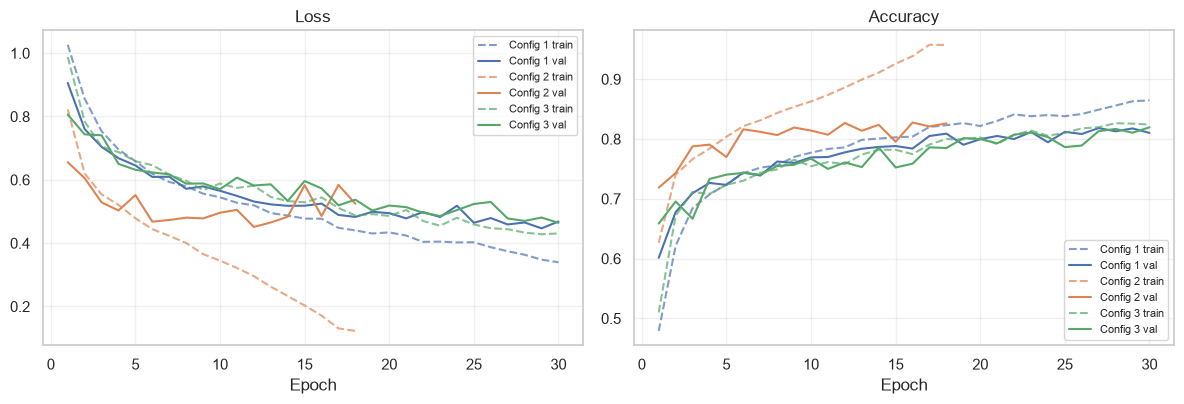

In [16]:
plot_history({n: histories[n] for n in CONFIGS}, FIG / "curves_configs.png"); plt.show()

## 5. Model 3 — MobileNetV2 (transfer learning)

MobileNetV2 pretrained on ImageNet; the last layer is replaced by Dropout(0.2) + Linear(1280 → 3).
Stage 1: only the new head is trained (3 epochs, backbone frozen). Stage 2: the whole network is fine-tuned with a
small learning rate (1e-4, cosine schedule, early stopping). Input 128×128, ImageNet normalization, augmentation.

{'Model': 'MobileNetV2 (frozen)', 'Val accuracy': 0.843, 'Test accuracy': 0.8382, 'Test loss': 0.4215, 'Test F1 (macro)': 0.8388, 'Best epoch': 2, 'Epochs run': 3, 'Training time (min)': 4.1861}


{'Model': 'MobileNetV2 (fine-tuned)', 'Val accuracy': 0.9341, 'Test accuracy': 0.9284, 'Test loss': 0.2137, 'Test F1 (macro)': 0.9284, 'Best epoch': 7, 'Epochs run': 10, 'Training time (min)': 28.0278}
MobileNetV2 parameters: 2,227,715


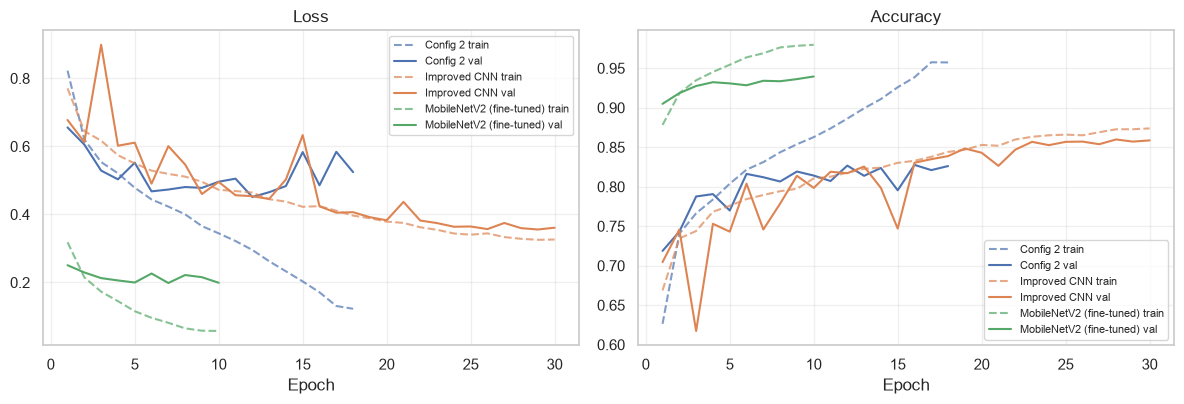

In [17]:
def make_mnv2_stage1():
    net = mobilenet_v2_transfer(pretrained=True, dropout=0.2)
    set_backbone_trainable(net, False)
    return net

cfg1 = TrainConfig("MobileNetV2 (frozen)", image_size=128, batch_size=64, micro_batch=64, epochs=3, patience=3,
                   lr=1e-3, optimizer="AdamW", weight_decay=1e-4, augment=1.0, mean=IMAGENET_MEAN, std=IMAGENET_STD)
run("MobileNetV2 (frozen)", make_mnv2_stage1, cfg1, "models/mobilenetv2_frozen.pt")

def make_mnv2_stage2():
    net = mobilenet_v2_transfer(pretrained=False, dropout=0.2)
    net.load_state_dict(torch.load("models/mobilenetv2_frozen.pt", map_location="cpu"))
    set_backbone_trainable(net, True)
    return net

cfg2 = TrainConfig("MobileNetV2 (fine-tuned)", image_size=128, batch_size=64, micro_batch=64, epochs=10, patience=4,
                   lr=1e-4, optimizer="AdamW", weight_decay=1e-4, augment=1.0, cosine_schedule=True,
                   mean=IMAGENET_MEAN, std=IMAGENET_STD)
run("MobileNetV2 (fine-tuned)", make_mnv2_stage2, cfg2, "models/mobilenetv2_pedcrops.pt")
for name in ["MobileNetV2 (frozen)", "MobileNetV2 (fine-tuned)"]:
    row, probs_[name] = eval_row(name); print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})
print("MobileNetV2 parameters:", f"{count_params(models_['MobileNetV2 (fine-tuned)'])[0]:,}")
plot_history({n: histories[n] for n in ["Config 2", "Improved CNN", "MobileNetV2 (fine-tuned)"]},
             FIG / "curves_improvement.png"); plt.show()

## 6. Comparison of the three models on the test set

Model 1 = best classical pipeline, Model 2 = improved CNN, Model 3 = fine-tuned MobileNetV2. The 95 %
confidence intervals come from a **bootstrap** of the 3,085 test crops (1,000 resamples).

In [18]:
FINAL = {"Model 1: HOG + SVM": pred_svm,
         "Model 2: own CNN (improved)": probs_["Improved CNN"].argmax(1).numpy(),
         "Model 3: MobileNetV2 (fine-tuned)": probs_["MobileNetV2 (fine-tuned)"].argmax(1).numpy()}
rng = np.random.default_rng(0)
BOOT = [rng.integers(0, len(yt_np), len(yt_np)) for _ in range(1000)]

def boot(pred):
    acc = [(pred[i] == yt_np[i]).mean() for i in BOOT]
    f1 = [f1_score(yt_np[i], pred[i], average="macro") for i in BOOT]
    return np.percentile(acc, [2.5, 97.5]), np.percentile(f1, [2.5, 97.5])

# speed for one busy frame: 16 boxes at once (like in public.safe), time per box
@torch.no_grad()
def time_cnn(name, n=16, reps=30):
    net, cfg = models_[name], configs[name]
    sync = torch.mps.synchronize if device.type == "mps" else (torch.cuda.synchronize if device.type == "cuda" else (lambda: None))
    for _ in range(3): net(prepare_batch(x_test[:n], device, cfg.image_size, cfg.mean, cfg.std))  # warm-up
    sync(); t = time.perf_counter()
    for _ in range(reps): net(prepare_batch(x_test[:n], device, cfg.image_size, cfg.mean, cfg.std))
    sync(); return (time.perf_counter() - t) / reps / n * 1000

svm.predict(hog_features(x_test[:16], n_jobs=1)); t = time.perf_counter()
for _ in range(10): svm.predict(hog_features(x_test[:16], n_jobs=1))
svm_ms = (time.perf_counter() - t) / 10 / 16 * 1000
speed = {"Model 1: HOG + SVM": (svm_ms, "CPU, 1 core"),
         "Model 2: own CNN (improved)": (time_cnn("Improved CNN"), device.type),
         "Model 3: MobileNetV2 (fine-tuned)": (time_cnn("MobileNetV2 (fine-tuned)"), device.type)}
size = {"Model 1: HOG + SVM": Path("models/hog_svm.joblib").stat().st_size / 1e6,
        "Model 2: own CNN (improved)": Path("models/pedcnn_improved.pt").stat().st_size / 1e6,
        "Model 3: MobileNetV2 (fine-tuned)": Path("models/mobilenetv2_pedcrops.pt").stat().st_size / 1e6}
rows = []
for name, pred in FINAL.items():
    m = metrics_dict(yt_np, pred); ci_acc, ci_f1 = boot(pred)
    rows.append({"Model": name, "Accuracy": m["accuracy"], "Accuracy 95 % CI": f"{ci_acc[0]:.3f}–{ci_acc[1]:.3f}",
                 "Precision (macro)": m["precision_macro"], "Recall (macro)": m["recall_macro"],
                 "F1 (macro)": m["f1_macro"], "F1 95 % CI": f"{ci_f1[0]:.3f}–{ci_f1[1]:.3f}",
                 "Pedestrian precision": m["precision_pedestrian"], "Pedestrian recall": m["recall_pedestrian"],
                 "ms per box (frame of 16)": speed[name][0], "measured on": speed[name][1], "model file (MB)": size[name]})
final_table = pd.DataFrame(rows).set_index("Model")
final_table.to_csv(RESULTS / "final_comparison.csv")
final_table.round(4)

,Accuracy,Accuracy 95 % CI,Precision (macro),Recall (macro),F1 (macro),F1 95 % CI,Pedestrian precision,Pedestrian recall,ms per box (frame of 16),measured on,model file (MB)
Model,,,,,,,,,,,
Model 1: HOG + SVM,0.7841,0.768–0.798,0.7803,0.7803,0.7792,0.763–0.794,0.6779,0.7185,5.7844,"CPU, 1 core",44.6526
Model 2: own CNN (improved),0.8535,0.841–0.865,0.8509,0.8508,0.8502,0.838–0.862,0.8223,0.8098,0.9964,mps,1.0114
Model 3: MobileNetV2 (fine-tuned),0.9284,0.920–0.937,0.9281,0.9289,0.9284,0.920–0.937,0.9252,0.9413,3.7506,mps,9.1553


Model 3: MobileNetV2 (fine-tuned) − Model 2: own CNN (improved): accuracy difference +7.5 pp, 95 % CI [+6.2, +8.8] pp
Model 2: own CNN (improved) − Model 1: HOG + SVM: accuracy difference +7.0 pp, 95 % CI [+5.6, +8.4] pp


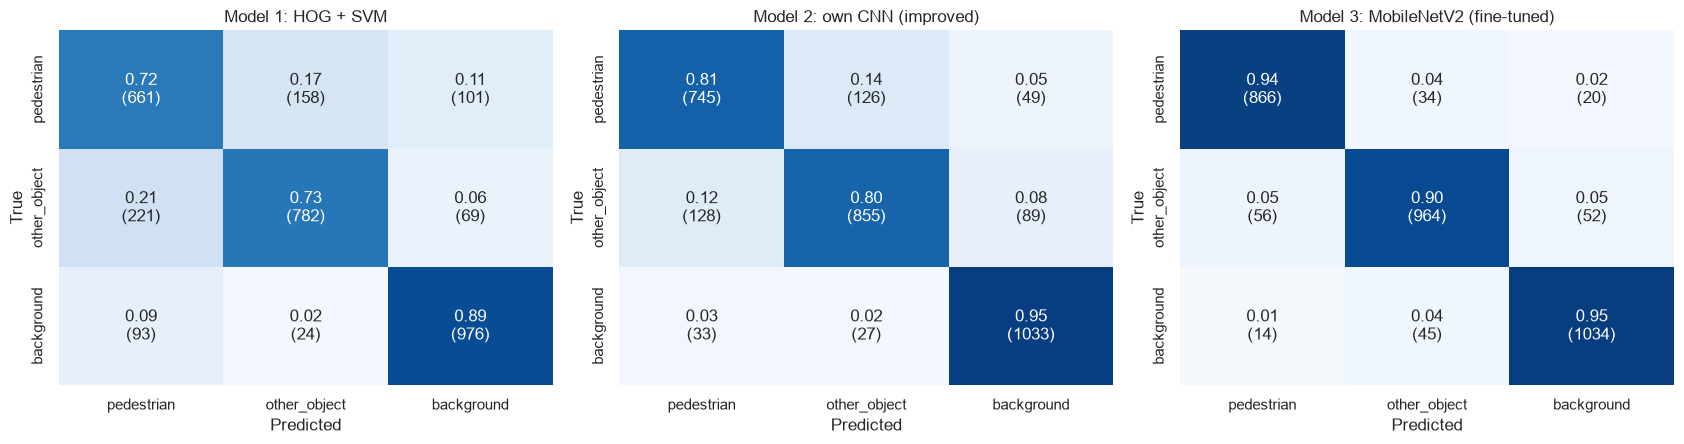

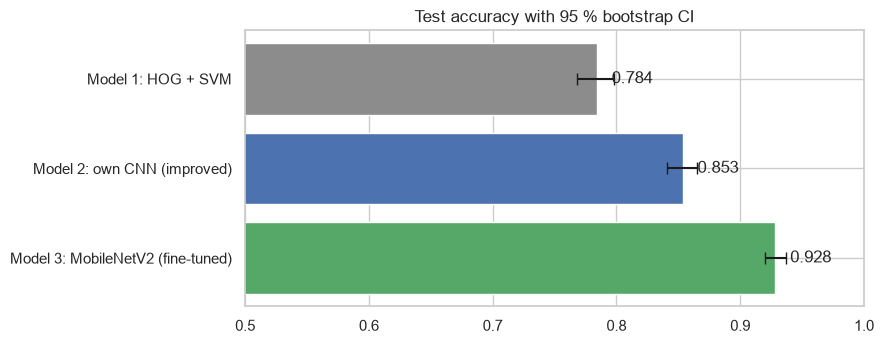

In [19]:
# paired bootstrap: is the difference between two models real?
names = list(FINAL)
for a, b in [(names[2], names[1]), (names[1], names[0])]:
    d = [((FINAL[a][i] == yt_np[i]).mean() - (FINAL[b][i] == yt_np[i]).mean()) for i in BOOT]
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"{a} − {b}: accuracy difference {np.mean(d) * 100:+.1f} pp, 95 % CI [{lo * 100:+.1f}, {hi * 100:+.1f}] pp")

from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (name, pred) in zip(axes, FINAL.items()):
    cm = confusion_matrix(yt_np, pred, labels=range(3)); cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f"{cmn[i, j]:.2f}\n({cm[i, j]})" for j in range(3)] for i in range(3)]), fmt="",
                cmap="Blues", cbar=False, ax=ax, xticklabels=CLASSES, yticklabels=CLASSES, vmin=0, vmax=1)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
fig.tight_layout(); fig.savefig(FIG / "confusion_three_models.png", dpi=140); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
acc = [final_table.loc[n, "Accuracy"] for n in names]
err = np.array([[acc[k] - float(final_table.loc[n, "Accuracy 95 % CI"].split("–")[0]),
                 float(final_table.loc[n, "Accuracy 95 % CI"].split("–")[1]) - acc[k]] for k, n in enumerate(names)]).T
ax.barh(names, acc, xerr=err, color=["C7", "C0", "C2"], capsize=4)
for k, v in enumerate(acc): ax.text(v + 0.012, k, f"{v:.3f}", va="center")
ax.set_xlim(0.5, 1.0); ax.set_title("Test accuracy with 95 % bootstrap CI"); ax.invert_yaxis()
fig.tight_layout(); fig.savefig(FIG / "accuracy_three_models.png", dpi=150); plt.show()

## 7. Practical application — the three models as a filter for real YOLOv8n boxes

`scripts/make_yolo_detections.py` ran **YOLOv8n** (the same weights as in public.safe, confidence 0.30) on the
**738 test photos**: 1,184 "person" boxes, 939 true positives (IoU ≥ 0.5 with a COCO person) and 245 false
positives. Every model looks at every box. Rule: the CNNs keep a box if $P(\text{pedestrian}) \ge 0.5$, the SVM
keeps it if the predicted class is *pedestrian*.

In [20]:
DET = Path("data/yolo_test_detections")
det = pd.read_csv(DET / "detections.csv")
ysum = json.loads((DET / "summary.json").read_text())
with zipfile.ZipFile(DET / "crops.zip") as zf:
    x_det = torch.from_numpy(np.stack([np.asarray(Image.open(io.BytesIO(zf.read(f"{d}.jpg"))).convert("RGB"))
                                       for d in det.det_id])).permute(0, 3, 1, 2).contiguous()
dummy = torch.zeros(len(det), dtype=torch.long)
keep = {"YOLOv8n only": np.ones(len(det), bool),
        "Model 1: HOG + SVM": svm.predict(hog_features(x_det)) == 0}
for label, name in [("Model 2: own CNN (improved)", "Improved CNN"), ("Model 3: MobileNetV2 (fine-tuned)", "MobileNetV2 (fine-tuned)")]:
    _, _, p = evaluate(models_[name], x_det, dummy, configs[name], device)
    keep[label] = p[:, 0].numpy() >= 0.5
    if "MobileNet" in label: det["p_ped"] = p[:, 0].numpy()
tp = det.is_tp.to_numpy()
rows = []
for label, k in keep.items():
    tp_k, fp_k = int((k & tp).sum()), int((k & ~tp).sum())
    rows.append({"Filter": label, "True pedestrians kept": tp_k, "True pedestrians lost %": 100 * (1 - tp_k / tp.sum()),
                 "False positives left": fp_k, "False positives removed %": 100 * (1 - fp_k / (~tp).sum()),
                 "Precision": tp_k / max(1, k.sum()), "Recall": tp_k / ysum["gt_persons"]})
practical = pd.DataFrame(rows).set_index("Filter")
practical.to_csv(RESULTS / "practical_three_models.csv")
practical.round(3)

,True pedestrians kept,True pedestrians lost %,False positives left,False positives removed %,Precision,Recall
Filter,,,,,,
YOLOv8n only,939,0.000,245,0.000,0.793,0.603
Model 1: HOG + SVM,729,22.364,166,32.245,0.815,0.468
Model 2: own CNN (improved),796,15.229,195,20.408,0.803,0.511
Model 3: MobileNetV2 (fine-tuned),903,3.834,213,13.061,0.809,0.580


In [21]:
# MobileNetV2: effect of the threshold (the operator of public.safe can choose it)
sweep = []
for t in [0.0, 0.3, 0.5, 0.7, 0.9]:
    k = det.p_ped.to_numpy() >= t
    sweep.append({"threshold": t, "TP kept %": 100 * (k & tp).sum() / tp.sum(),
                  "FP removed %": 100 * (1 - (k & ~tp).sum() / (~tp).sum()),
                  "precision": (k & tp).sum() / max(1, k.sum()), "recall": (k & tp).sum() / ysum["gt_persons"]})
pd.DataFrame(sweep).set_index("threshold").round(3)

,TP kept %,FP removed %,precision,recall
threshold,,,,
0.0,100.000,0.000,0.793,0.603
0.3,96.912,10.204,0.805,0.584
0.5,96.166,13.061,0.809,0.580
0.7,94.675,15.918,0.812,0.571
0.9,91.161,22.449,0.818,0.550


**Why are so few false positives removed?** In my endterm I checked the boxes by hand: 114 of the 245 "false
positives" cover a part of a real person (IoU 0.3–0.5), and among 40 random "no person" boxes that MobileNetV2 kept,
**27 show a real person without a COCO label**, 5 are real mistakes (toy, dog, statue, hydrant, donkey) and 8 are
unclear. So the COCO labels make the measured reduction pessimistic.

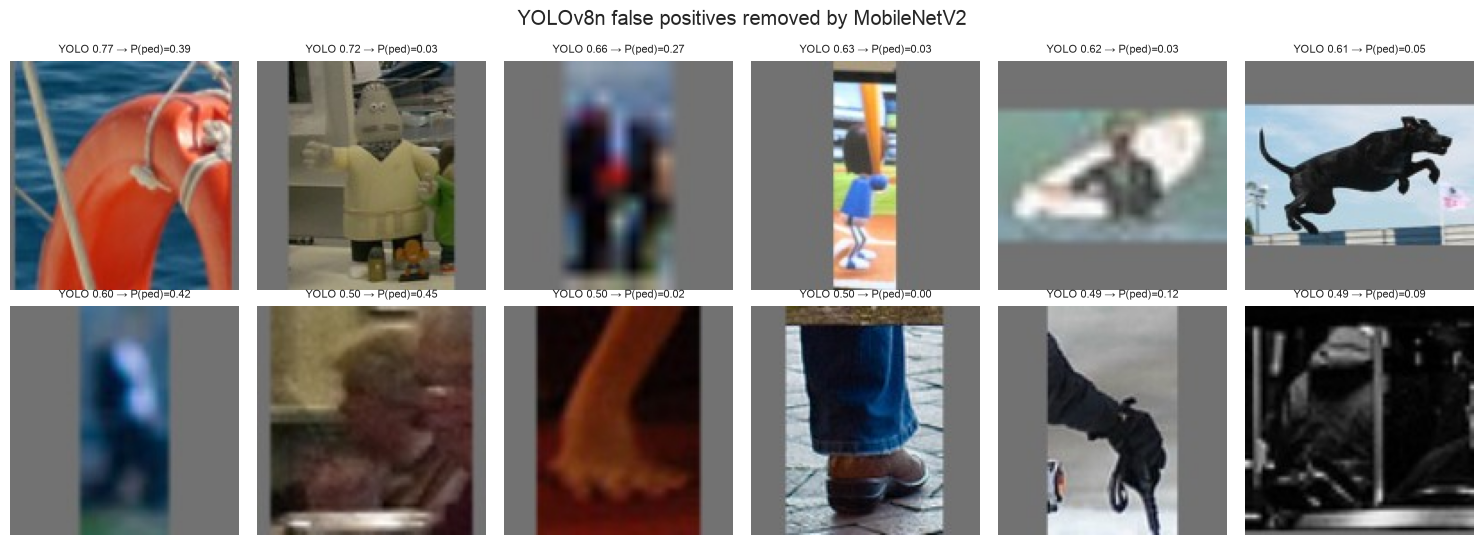

In [22]:
fp_rej = det[(~det.is_tp) & (det.p_ped < 0.5)].sort_values("conf", ascending=False).head(12)
with zipfile.ZipFile(DET / "crops.zip") as zf:
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.6))
    for ax, r in zip(axes.ravel(), fp_rej.itertuples()):
        ax.imshow(Image.open(io.BytesIO(zf.read(f"{r.det_id}.jpg")))); ax.axis("off")
        ax.set_title(f"YOLO {r.conf:.2f} → P(ped)={r.p_ped:.2f}", fontsize=8)
fig.suptitle("YOLOv8n false positives removed by MobileNetV2"); fig.tight_layout()
fig.savefig(FIG / "yolo_rejected.png", dpi=110); plt.show()

## 8. Working program — web application

`app.py` is a small web application (Gradio). The user uploads a photo or takes one with the camera, chooses one
of my three models and the threshold, and sees the YOLOv8n boxes: green = kept as pedestrian, red = rejected,
with a table of all boxes and the time of YOLOv8n and of the verifier.

```bash
python app.py            # local, open http://127.0.0.1:7860
python app.py --share    # public link (works in Google Colab too)
```

`src/verified_detector.py` contains the same pipeline as a class with the `detect()` method of the public.safe
detector, so it can replace the detector of my diploma system without other changes.

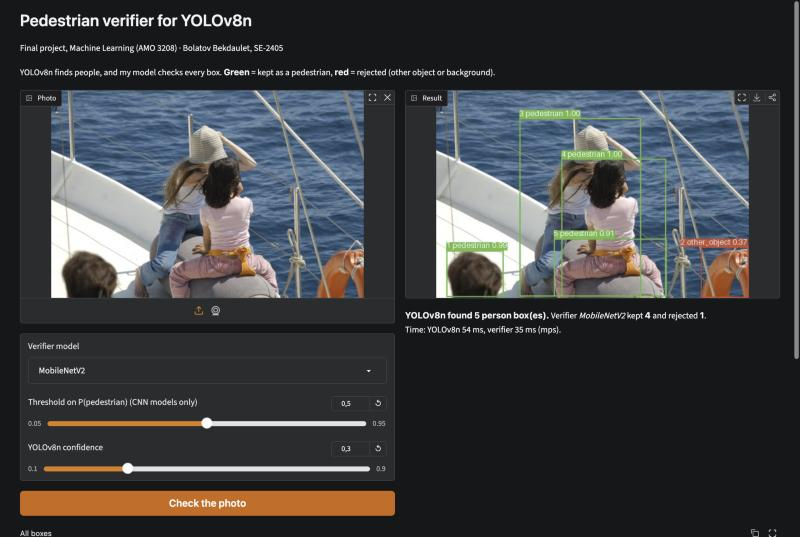

In [23]:
from IPython.display import Image as ShowImage, display
shot = FIG / "app_screenshot.png"
display(ShowImage(filename=str(shot), width=900)) if shot.exists() else print("run app.py to see the application")

## Conclusion

1. **Data:** *PedCrops v1* – 21,669 crops (3 × 7,223) from COCO val2017, split by photo 15,260 / 3,324 / 3,085.
2. **Three models:** HOG + PCA + RBF SVM (classical), own CNN (3 configurations + improved), MobileNetV2 (transfer learning).
3. **Preprocessing:** HOG raised the classical model from 48.4 % (raw pixels) to 74.5 %; PCA kept 95 % of the variance
   with 469 of 1,764 features (−0.5 points, 4× faster); the three CNN configurations reached 80.5–80.8 %, BatchNorm +
   Dropout + augmentation 85.3 %.
4. **Best model:** MobileNetV2 – **92.8 %** accuracy (95 % CI 92.0–93.7 %), macro F1 0.928, pedestrian recall 94.1 %;
   +7.5 points over my CNN (CI +6.2 … +8.8) and +14.4 points over HOG + SVM.
5. **Practical test:** on 1,184 real YOLOv8n boxes MobileNetV2 removes 13.1 % of the false positives and keeps 96.2 % of
   the true pedestrians; HOG + SVM and the CNN remove more false positives but lose 22.4 % and 15.2 % of the people.
6. **Working program:** `app.py` (web application) and `src/verified_detector.py` (drop-in detector for public.safe).

The report (`report/Final_Report_Bolatov_Bekdaulet.pdf`) explains all results.